In [1]:
import hyrax
import hyrax_seldon
import lsdb

In [2]:
dp2 = lsdb.open_catalog(
    '/astro/store/shire/hats/catalogs/rubin_dp2/dia_object_collection',
    columns=[
        "diaObjectId",
        "nDiaSources",
        "diaObjectForcedSource.band",
        "diaObjectForcedSource.midpointMjdTai",
        "diaObjectForcedSource.psfDiffFlux",
        "diaObjectForcedSource.psfDiffFluxErr",
        "diaObjectForcedSource.psfDiffFlux_flag",
        "diaObjectForcedSource.diff_PixelFlags_nodataCenter",
        "diaObjectForcedSource.pixelFlags_saturatedCenter",
        "diaObjectForcedSource.invalidPsfFlag",
        
    ],
    filters=[("nDiaSources", ">=", 32)],
)

dp2_no_flag = dp2.query(
    "diaObjectForcedSource.psfDiffFlux.notna()"
    " & diaObjectForcedSource.psfDiffFluxErr.notna()"
    " & ~diaObjectForcedSource.psfDiffFlux_flag"
    " & ~diaObjectForcedSource.diff_PixelFlags_nodataCenter"
    " & ~diaObjectForcedSource.pixelFlags_saturatedCenter"
    " & ~diaObjectForcedSource.invalidPsfFlag"
)

dp2_many_sources = dp2_no_flag.query("diaObjectForcedSource.len() >= 32")

def add_photflag(df):
    df["diaObjectForcedSource.photFlag"] = (df["diaObjectForcedSource.psfDiffFlux"] / df["diaObjectForcedSource.psfDiffFluxErr"] > 5).astype("int")*4096
    return df


dp2_many_sources = dp2_many_sources.map_partitions(add_photflag)

In [3]:
from hyrax import Hyrax
from hyrax.datasets import LSDBStreamDataset

h = Hyrax()

In [4]:
%env CUDA_VISIBLE_DEVICES=1
h.set_config("general.distributed", False)

env: CUDA_VISIBLE_DEVICES=1


In [5]:
LSDBStreamDataset.register_catalog("dp2_filtered_catalog", dp2_many_sources)

data_request = {
    "infer_stream": {
        "data": {
            "dataset_class": "LSDBStreamDataset",
            "data_location": "lsdb://dp2_filtered_catalog",
            "primary_id_field": "diaObjectId",
            "fields": [
                "diaObjectForcedSource_midpointMjdTai",
                "diaObjectForcedSource_band",
                "diaObjectForcedSource_psfDiffFlux",
                "diaObjectForcedSource_psfDiffFluxErr",
                "diaObjectForcedSource_photFlag",
            ],
        }
    }
}
h.set_config("data_request", data_request)

h.set_config("data_set.LSDBStreamDataset.stream_type", "catalog")
h.set_config("data_set.LSDBStreamDataset.shuffle", False)
h.set_config("data_set.LSDBStreamDataset.seed", 2015)

h.set_config("data_loader.batch_size", 250)

In [6]:
h.set_config("model.name", "hyrax_seldon.models.seldon.HyraxSeldon")
h.set_config("infer_stream.model_weights_file", "./epoch=1086-val_loss=1.18.ckpt")
h.set_config("infer_stream.save_model_output", True)
h.set_config("model.HyraxSeldon.seldon_config", "./hparams.yaml")
h.set_config("model.HyraxSeldon.mjd_field_name", "diaObjectForcedSource_midpointMjdTai")
h.set_config("model.HyraxSeldon.flux_field_name", "diaObjectForcedSource_psfDiffFlux")
h.set_config("model.HyraxSeldon.flux_err_field_name", "diaObjectForcedSource_psfDiffFluxErr")
h.set_config("model.HyraxSeldon.band_field_name", "diaObjectForcedSource_band")
h.set_config("model.HyraxSeldon.phot_flag_field_name", "diaObjectForcedSource_photFlag")

[2026-11-19 15:00:38,450 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-19 15:00:38,463 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-19 15:00:38,477 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-19 15:00:38,491 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-19 15:00:38,505 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-19 15:00:38,519 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/

In [7]:
import tqdm

batch_counter = 0
MAX_BATCHES = 400

with h.infer_stream() as session:
    for batch, metrics in tqdm.tqdm(session):
        batch_counter += 1

        if batch_counter >= MAX_BATCHES:
            break

[2026-11-19 15:00:40,059 hyrax.models.model_registry:INFO] Setting model's self.optimizer from config: torch.optim.SGD with arguments: {'lr': 0.01, 'momentum': 0.9}.
[2026-11-19 15:00:40,060 hyrax.models.model_registry:INFO] Setting model's self.criterion from config: torch.nn.CrossEntropyLoss with default arguments.
[2026-11-19 15:00:40,060 hyrax.models.model_registry:INFO] Setting model's self.scheduler from config: torch.optim.lr_scheduler.ExponentialLR
with arguments: {'gamma': 1}.
2026-11-19 15:00:40,129 ignite.distributed.auto.auto_dataloader INFO: Use data loader kwargs for dataset '<hyrax.datasets.stre': 
	{'batch_size': None, 'collate_fn': <bound method CollationMixin.collate of <hyrax.datasets.streaming_data_provider.StreamingDataProvider object at 0x7f3e669a2a50>>, 'num_workers': 0, 'pin_memory': True}
[2026-11-19 15:00:43,032 hyrax.models.model_utils:INFO] Updated config['infer_stream']['model_weights_file'] to: epoch=1086-val_loss=1.18.ckpt
[2026-11-19 15:00:43,067 hyrax.v

In [8]:
from hyrax.datasets.result_dataset import ResultDataset
from hyrax.config_utils import find_most_recent_results_dir

infer_dir = find_most_recent_results_dir(h.config, "infer_stream")
a = ResultDataset({}, data_location = infer_dir)

In [9]:
for i in range(15):
    print(a[i]['z'])

[-2.0122473   3.628693    0.6229025   0.5991382  -0.20266117  0.11732279]
[-2.015365    4.063295   -0.02361833  0.39351282  0.22334483 -1.1172448 ]
[-1.1783714   1.9994226  -0.08241542  0.67037106  0.20326002 -2.2102983 ]
[-2.2618487   2.824852   -0.26063377  0.5455109   1.2196884  -0.21763793]
[-2.404425    3.0171354  -0.09389815  1.0828382   0.11114937 -0.19978967]
[-0.52823997  2.54277     1.1070628  -0.49611127  1.0599856  -2.0005674 ]
[-2.3987968  2.758618  -0.4971839  0.4519809  1.2376535  0.0524225]
[-1.02562     3.6163077   0.20783724  0.5424719   0.7374428  -2.330383  ]
[-1.9803075   4.670252    0.55110776  0.41758275 -0.04074221  0.6248781 ]
[-2.2393088   4.1681104   0.1347731   0.5205054   0.11682147 -0.968318  ]
[-1.3255285   4.0712175   0.6945446   0.36363986  0.2593473   0.808248  ]
[-1.7189788   4.280931    0.6489596   0.28808242  0.16172473  0.7850116 ]
[-1.768618    2.4717715  -0.24253729  1.0841521   0.38186327 -0.6405829 ]
[-1.6405402   4.592407    0.3750326  -0.0556

In [10]:
from hyrax.config_utils import find_most_recent_results_dir

infer_dir = str(find_most_recent_results_dir(h.config, "infer_stream"))

data_request = {
    "reduce_dimensions": {
        "data": {
            "dataset_class": "ResultDataset",
            "data_location": infer_dir,
            "primary_id_field": "id",
            "fields": ['z'],
        }
    }
}

h.set_config("data_request", data_request)

umap_results = h.reduce_dimensions(algorithm="umap")

[2026-11-19 15:44:53,480 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-19 15:44:53,492 hyrax.config_utils:WARNING] Runtime config contains key or section 'reduce_dimensions' which has no default defined. All configuration keys and sections must be defined in /astro/store/shiren/awoldag/code/hyrax/src/hyrax/hyrax_default_config.toml
[2026-11-19 15:44:54,130 hyrax.verbs.reduce_dimensions:INFO] Saving reduction results using umap to /astro/users/awoldag/code/hyrax_seldon/results/20261119-154454-umap-xB-S
[2026-11-19 15:44:54,131 hyrax.verbs.reduce_dimensions:INFO] Using configured [data_request.reduce_dimensions] to load dataset for reduction.
[2026-11-19 15:44:54,137 hyrax.verbs.reduce_dimensions:INFO] Using field 'z' for dimensionality reduction.
[2026-11-19 15:44:55,925 hyrax.verbs.reduce_dimensions:INFO] No model_path specified. A new model will be fitted.
[2026-11-19 15:44:55,9

Creating lower dimensional representation using UMAP::   0%|          | 0/98 [00:00<?, ?it/s]

[2026-11-19 15:50:19,862 hyrax.datasets.result_dataset:INFO] Optimizing Lance table after 98 batches
[2026-11-19 15:50:19,937 hyrax.datasets.result_dataset:INFO] Lance table optimization complete
[2026-11-19 15:50:19,937 hyrax.verbs.reduce_dimensions:INFO] Finished transforming all data with umap


In [11]:
import numpy as np

# Stack all UMAP embeddings into a single array.
umap_embeddings = np.array([umap_results[i]["data"] for i in range(len(umap_results))])
print(f"Shape: {umap_embeddings.shape}  (samples × components)")

Shape: (100000, 2)  (samples × components)


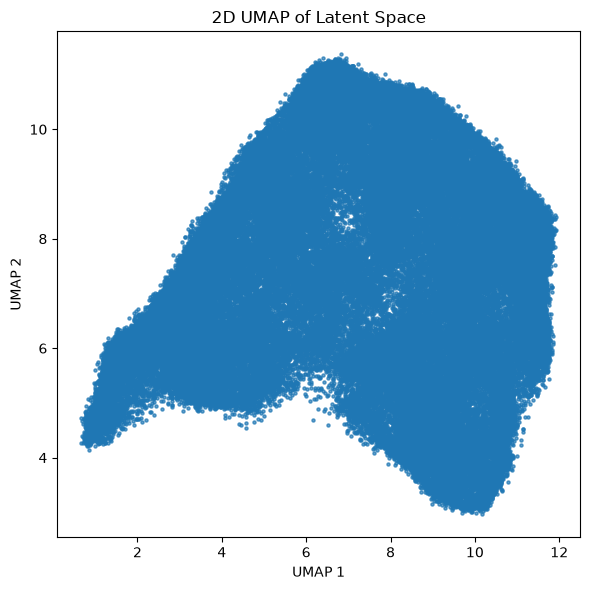

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], s=5, alpha=0.7)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("2D UMAP of Latent Space")
plt.tight_layout()
plt.show()